# Basic usage

The three model families of the paper are built in one call each: `grid_cell_model`,
`place_cell_model` and `remapping_model` build the generators, wrap them in an `ExponentialMap`
or a `RemappingModel` and return the model with the canonical origin state $\mathbf{p}_0$. This
notebook goes from positions to population vectors, rate maps and similarity with each of the
three, then builds a model from the parts the constructors use. Every random draw is seeded.

The models have 150 units, about half the sizes in the paper, so each cell runs in a few
seconds.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch

import expmap
from expmap.analysis import batch_inference, compute_ratemaps, compute_similarity
from expmap.plotting import ratemap_collage
from expmap.simulation import generate_uniform_positions

SEED = 0
ARENA_SIZE = 10  # positions run over [-ARENA_SIZE, ARENA_SIZE] in each direction
BINS = 32
N_BATCHES, BATCH_SIZE = 400, 50  # 20,000 positions, about 20 per rate map bin

EXTENT = (-ARENA_SIZE, ARENA_SIZE, -ARENA_SIZE, ARENA_SIZE)
edges = np.linspace(-ARENA_SIZE, ARENA_SIZE, BINS + 1)
centers = (edges[:-1] + edges[1:]) / 2

## A grid cell model

`grid_cell_model` places the eigenvalues of the generators on a ring, at the $M$-th roots of
unity. This is the metric-preserving spectrum of Sec. 2.4. With $M = 3$ the plane waves are
$60^\circ$ apart and the units have hexagonal grid fields. The model is an `nn.Module` that maps
a batch of positions, shape `(batch_size, 2)`, to population vectors, shape `(batch_size, N)`.
`batch_inference` runs it over a list of position batches and returns a numpy array, and
`compute_ratemaps` bins the activity by position.


N = 150 units


population vectors (20000, 150), rate maps (150, 32, 32)


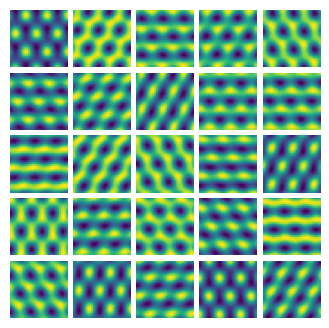

In [2]:
model, p0 = expmap.grid_cell_model(M=3, n_copies=25, seed=SEED)
print(f"N = {len(p0)} units")

position_batches = generate_uniform_positions(N_BATCHES, BATCH_SIZE, ARENA_SIZE, seed=SEED)
positions = np.concatenate(position_batches)

p = batch_inference(model, position_batches, p0, progress=False)
ratemaps = compute_ratemaps(positions[:, 0], positions[:, 1], p, bins=BINS)
print(f"population vectors {p.shape}, rate maps {ratemaps.shape}")

fig, _ = ratemap_collage(ratemaps[:25], rows=5, cols=5, figsize=(4, 4))

The generators are skew-symmetric, so the matrix exponential is orthogonal and every population
vector has the norm of $\mathbf{p}_0$: the representation is equinorm (Sec. 2.3).


In [3]:
norms = np.linalg.norm(p, axis=1)
print(f"||p|| = {norms.mean():.6f} +/- {norms.std():.1e}  (||p0|| = {p0.norm():.6f})")

||p|| = 1.000001 +/- 1.1e-06  (||p0|| = 1.000000)


## Similarity depends only on displacement

In an equinorm representation the dot product of two population vectors is their cosine
similarity. When the generators also commute, it depends only on the displacement between the
two positions (Eq. 3). `compute_similarity` takes the population vector at a reference bin and
compares it with every other bin. The map below is in arena coordinates, with the reference bin
marked.


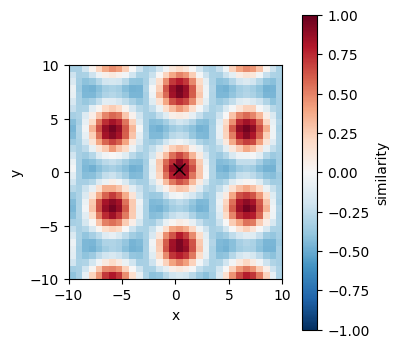

In [4]:
a = BINS // 2
similarity = compute_similarity(ratemaps, ref_bin=(a, a))

fig, ax = plt.subplots(figsize=(4, 3.4), layout="constrained")
im = ax.imshow(similarity.T, origin="lower", extent=EXTENT, cmap="RdBu_r", vmin=-1, vmax=1)
ax.plot(centers[a], centers[a], "kx", markersize=8)
ax.set_xlabel("x")
ax.set_ylabel("y")
fig.colorbar(im, ax=ax, label="similarity")
plt.show()

Eq. 4 gives this similarity in closed form, as a sum of cosines over the eigenvalue pairs. The
[`roots_of_unity` notebook](../notebooks/roots_of_unity.ipynb) compares the measured similarity
with the closed form.

## Place-like fields

`place_cell_model` draws the eigenvalues from a Gaussian instead of placing them on a ring. The
similarity function is then close to a Gaussian in the displacement, and the units have
localized, place-like fields (App. H). The steps are the same as above. The arena is the smaller
one of Appendix A, $(x, y) \in [-2, 2]$, because the similarity function of the default spectrum
falls to zero within about one arena unit.


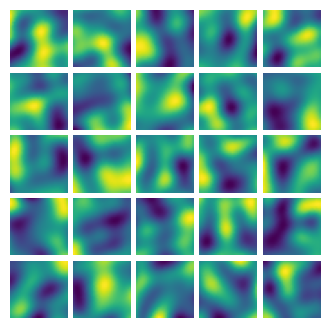

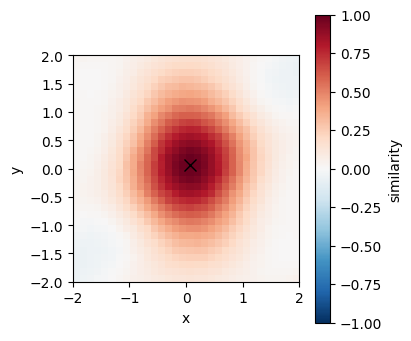

In [5]:
model, p0 = expmap.place_cell_model(N=150, seed=SEED)

PLACE_ARENA_SIZE = 2.0
place_batches = generate_uniform_positions(N_BATCHES, BATCH_SIZE, PLACE_ARENA_SIZE, seed=SEED)
place_positions = np.concatenate(place_batches)
place_extent = (-PLACE_ARENA_SIZE, PLACE_ARENA_SIZE, -PLACE_ARENA_SIZE, PLACE_ARENA_SIZE)
place_centers = centers * PLACE_ARENA_SIZE / ARENA_SIZE

p = batch_inference(model, place_batches, p0, progress=False)
ratemaps = compute_ratemaps(place_positions[:, 0], place_positions[:, 1], p, bins=BINS)
similarity = compute_similarity(ratemaps, ref_bin=(a, a))

# Orient the collage like the similarity map: x horizontal, y upward.
fig, _ = ratemap_collage(ratemaps[:25].transpose(0, 2, 1)[:, ::-1], rows=5, cols=5, figsize=(4, 4))

fig, ax = plt.subplots(figsize=(4, 3.4), layout="constrained")
im = ax.imshow(similarity.T, origin="lower", extent=place_extent, cmap="RdBu_r", vmin=-1, vmax=1)
ax.plot(place_centers[a], place_centers[a], "kx", markersize=8)
ax.set_xlabel("x")
ax.set_ylabel("y")
fig.colorbar(im, ax=ax, label="similarity")
plt.show()

## Remapping with a context signal

`remapping_model` adds a third generator $G_s$ for a scalar context $s$, so that
$\mathbf{p}(x, y, s) = e^{x G_x + y G_y + s G_s}\,\mathbf{p}_0$. The spatial generators are
those of the grid cell model, and the context generator has Gaussian eigenvalues. A context shift
leaves the similarity structure within a context unchanged and makes the maps of two contexts
nearly orthogonal (Sec. 2.5). The cell below evaluates the model on the bin centers at several
context values and measures the similarity of each map to the map at $s = 0$.


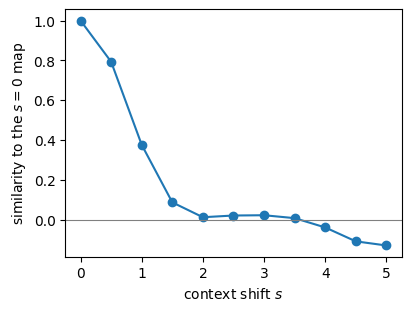

In [6]:
model, p0 = expmap.remapping_model(M=3, n_copies=25, seed=SEED)

X, Y = np.meshgrid(centers, centers, indexing="ij")
grid_positions = torch.tensor(np.stack([X.ravel(), Y.ravel()], axis=1), dtype=torch.float32)

contexts = np.linspace(0, 5, 11)
with torch.no_grad():
    p_reference = model(grid_positions, p0, context=0.0)
    between_context = [
        (model(grid_positions, p0, context=float(s)) * p_reference).sum(1).mean().item() for s in contexts
    ]

fig, ax = plt.subplots(figsize=(4, 3), layout="constrained")
ax.plot(contexts, between_context, "o-")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set_xlabel("context shift $s$")
ax.set_ylabel("similarity to the $s = 0$ map")
plt.show()

The rate maps of the same ten units in the two contexts share one color scale. The context shift
moves and reshapes the fields of each unit, and the periodicity of the lattice is unchanged
(Sec. 2.5).


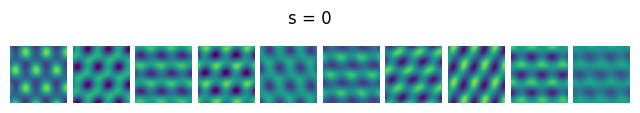

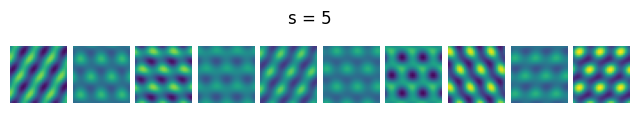

In [7]:
with torch.no_grad():
    maps = {s: model(grid_positions, p0, context=s).numpy().T.reshape(-1, BINS, BINS) for s in (0.0, 5.0)}

vmin = min(m[:10].min() for m in maps.values())
vmax = max(m[:10].max() for m in maps.values())
for s, m in maps.items():
    fig, _ = ratemap_collage(m[:10], rows=1, cols=10, figsize=(8, 1), vmin=vmin, vmax=vmax)
    fig.suptitle(f"s = {s:g}", y=1.15)

## Building a model from the parts

The constructors run four public steps. An eigenvalue specification becomes a pair of
block-diagonal skew-symmetric matrices $\Sigma_x$ and $\Sigma_y$, an orthogonal mixing matrix $R$
turns them into the generators $G = R^\top \Sigma R$, and the canonical origin state is
$\mathbf{p}_0 = R^\top \mathbf{1} / \sqrt{N}$ (App. C and I). The two generators share $R$ and
the block structure, so they commute and are skew-symmetric by construction. For the same seed,
the model built here is the model `grid_cell_model` returns.


In [8]:
from expmap.generators import block_diag_skew, build_generators, roots_of_unity_eigenvalues
from expmap.linalg import random_orthogonal_matrix, starting_state
from expmap.model import ExponentialMap

phi = roots_of_unity_eigenvalues(M=3, n_copies=25)  # angles on the unit ring
sigma_x = block_diag_skew(np.cos(phi))
sigma_y = block_diag_skew(np.sin(phi))

R = random_orthogonal_matrix(len(sigma_x), seed=SEED)
Gx, Gy = build_generators(sigma_x, sigma_y, R)
p0 = starting_state(R)
model = ExponentialMap(Gx, Gy)

print("commute:        ", torch.allclose(Gx @ Gy, Gy @ Gx, atol=1e-5))
print("skew-symmetric: ", torch.allclose(Gx, -Gx.T, atol=1e-6))

reference_model, reference_p0 = expmap.grid_cell_model(M=3, n_copies=25, seed=SEED)
with torch.no_grad():
    same = torch.allclose(model(grid_positions, p0), reference_model(grid_positions, reference_p0))
print("same as grid_cell_model:", same)

commute:         True
skew-symmetric:  True


same as grid_cell_model: True


## Bundling and querying

The hyperdimensional operations of Sec. 3.3 take population vectors as input. `bundle` averages
the population vectors of several locations into one memory, and `query` scores a state against
it. With place-like fields the score along a path is a sum of near-Gaussian bumps centered on
the stored locations (App. L.1). The
[`reward_navigation` notebook](../notebooks/reward_navigation.ipynb) adds a context per reward
map and navigates by gradient ascent on the score.


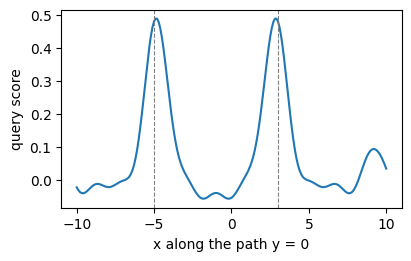

In [9]:
from expmap.navigation import bundle, query

model, p0 = expmap.place_cell_model(N=150, seed=SEED)

reward_positions = torch.tensor([[-5.0, 0.0], [3.0, 0.0]])
path = torch.stack([torch.linspace(-ARENA_SIZE, ARENA_SIZE, 201), torch.zeros(201)], dim=1)

with torch.no_grad():
    memory = bundle(model(reward_positions, p0))
    score = query(model(path, p0), memory)

fig, ax = plt.subplots(figsize=(4, 2.5), layout="constrained")
ax.plot(path[:, 0], score)
for x in reward_positions[:, 0]:
    ax.axvline(x, color="gray", linestyle="--", linewidth=0.8)
ax.set_xlabel("x along the path y = 0")
ax.set_ylabel("query score")
plt.show()

## Fitting to recorded cells

`expmap.fitting` is the only module that uses gradient descent. `CommutingGeneratorFit` recovers
$R$ and the wavevectors of the generators from measured rate maps, so the fitted generators
commute and are skew-symmetric by construction, and the fitted model extrapolates beyond the
arena it was fitted in (Sec. 3.2, App. K). The fits to the grid cells and to the CA1 place cells
are [`fit_grid_cells`](../notebooks/fit_grid_cells.ipynb) and
[`fit_place_cells`](../notebooks/fit_place_cells.ipynb), and the data they use are described on
the [data page](../data/README.md).
